# 06 — Warning time, event recall and alert burden

**Objective.** Determine how much advance warning the fixed models provide at constrained alert budgets.

**Cohort and interpretation.** Use frozen 2024–2025 predictions from notebook 03. Require a 7-day minimum warning and the model’s 14/30/60-day maximum horizon. Denominators include every eligible test-period injury event, even when no eligible warning outing exists; observable-event recall is separately shown. Multiple alerts are counted separately with no cooldown. This is the selected category-versus-IL-free cohort, not an operational full-league alert simulation.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config/injury_analysis.yaml").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src.injury_analysis.common import CFG, CACHE, OUT, read_table, table, conclusion, style
from src.injury_analysis.cohort import load
from src.injury_analysis import plots
style()
pd.set_option('display.max_columns', 14)


,category,horizon,qualifying_events,observable_events,alerted_events,injury_event_recall,observable_event_recall,precision,recall,median_warning_lead_days,false_alerts_per_pitcher_season
2,Elbow / UCL,14,145,103,17,0.117241,0.165049,0.025579,0.106061,11.0,1.214882
6,Elbow / UCL,30,145,104,25,0.172414,0.240385,0.054230,0.105932,17.0,1.092732
10,Elbow / UCL,60,145,108,38,0.262069,0.351852,0.232072,0.208594,28.0,0.763366
14,Shoulder,14,161,113,22,0.136646,0.194690,0.044350,0.158696,12.0,1.195289
18,Shoulder,30,161,117,29,0.180124,0.247863,0.078417,0.128386,18.0,1.074664
22,Shoulder,60,161,118,41,0.254658,0.347458,0.196850,0.148038,33.0,0.808722
26,Forearm,14,46,35,7,0.152174,0.200000,0.014724,0.164384,13.0,1.227829
30,Forearm,30,46,36,8,0.173913,0.222222,0.034533,0.168459,26.5,1.116398
34,Forearm,60,46,37,9,0.195652,0.243243,0.099897,0.212719,30.0,0.897331
38,Other arm,14,45,33,2,0.044444,0.060606,0.005521,0.060403,9.5,1.237405


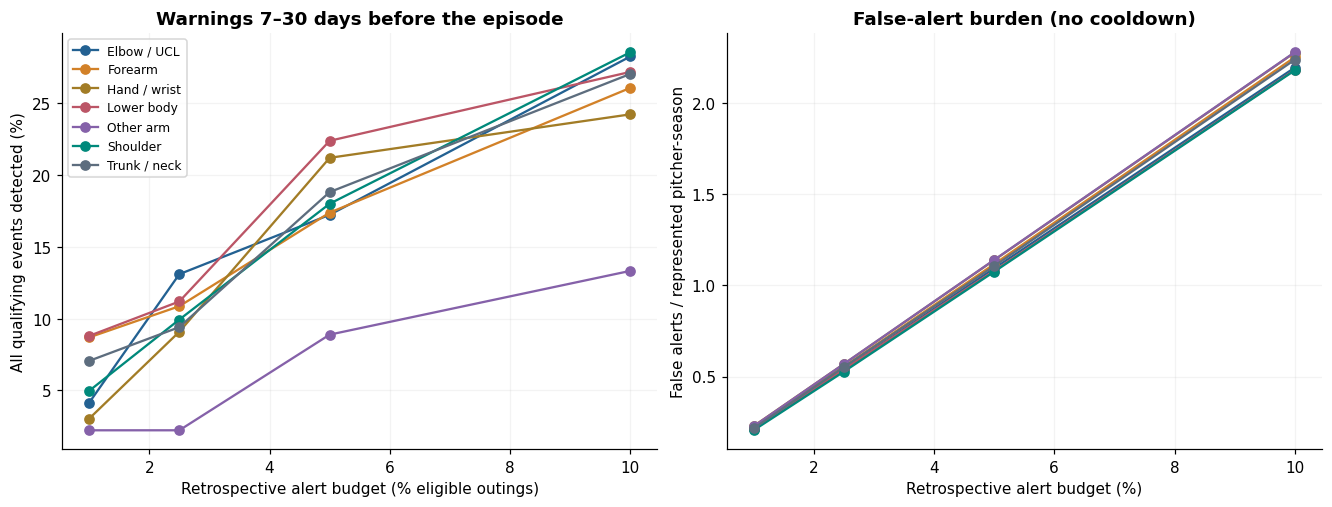

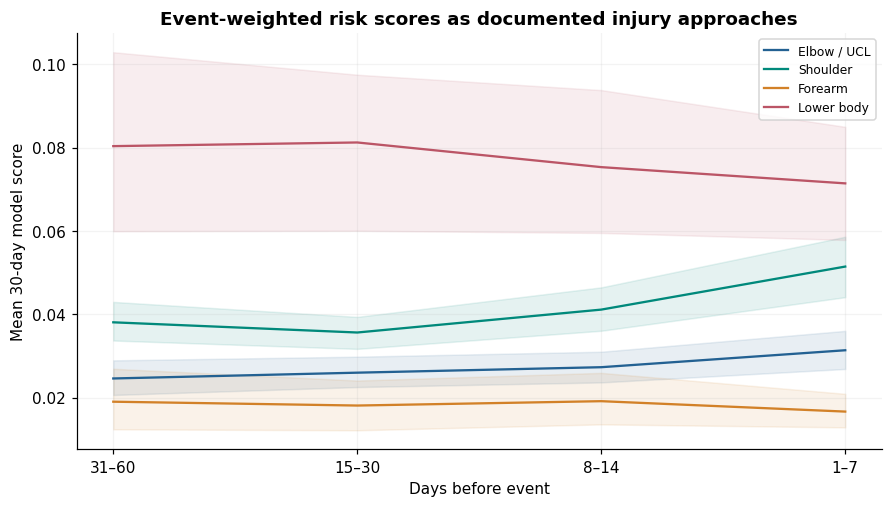

In [2]:
from src.injury_analysis.outcomes import warning_timing
a, events, spec = load()
risk = warning_timing(events)
budgets = read_table('alert_budget_metrics')
display(budgets.query('alert_rate == 0.05')[['category','horizon','qualifying_events','observable_events','alerted_events','injury_event_recall','observable_event_recall','precision','recall','median_warning_lead_days','false_alerts_per_pitcher_season']])
plots.warning_figure(); plt.show()
plots.risk_trajectory_figure(); plt.show()

## Retrospective budgets versus validation-fixed thresholds
Top-5% test ranking fixes the retrospective test alert budget; it is not a deployable threshold. A separate validation-score quantile fixes the threshold before test evaluation, and its realized test alert rate may drift. Warning lead time below is the earliest qualifying alert among **detected** events, not all events; missed events remain in recall denominators.

In [3]:
fixed = read_table('validation_fixed_thresholds')
display(fixed.query('horizon == 30 and validation_alert_budget == 0.05'))
leads = read_table('warning_lead_times')
display(leads.query('horizon == 30 and alert_rate == 0.05').groupby('category').warning_lead_days.agg(['count','median','min','max']))
b=budgets.query('horizon == 30 and alert_rate == 0.05')
conclusion(f"At a retrospective 5% budget, 7–30-day warning detects {b.injury_event_recall.min():.1%}–{b.injury_event_recall.max():.1%} of all qualifying category events. False alerts range from {b.false_alerts_per_pitcher_season.min():.2f} to {b.false_alerts_per_pitcher_season.max():.2f} per represented pitcher-season. Lead-time medians describe detected events only; substantial missed-event burden remains.")

,category,horizon,validation_alert_budget,threshold,validation_actual_rate,test_actual_rate,test_precision,test_recall,alerts,positives
6,Elbow / UCL,30,0.05,0.049906,0.050007,0.040304,0.058296,0.091808,1115,708
18,Shoulder,30,0.05,0.063415,0.050015,0.054772,0.075509,0.135453,1523,849
30,Forearm,30,0.05,0.033289,0.050004,0.060875,0.034982,0.207885,1658,279
42,Other arm,30,0.05,0.028576,0.050032,0.045672,0.008850,0.042471,1243,259
54,Trunk / neck,30,0.05,0.066177,0.050007,0.060676,0.040289,0.148559,1663,451
66,Lower body,30,0.05,0.102426,0.050020,0.077737,0.068531,0.231132,2145,636
78,Hand / wrist,30,0.05,0.035505,0.050017,0.048583,0.009863,0.075581,1318,172


,count,median,min,max
category,,,,
Elbow / UCL,25,17.0,7,30
Forearm,8,26.5,7,30
Hand / wrist,7,12.0,7,24
Lower body,28,24.5,7,30
Other arm,4,27.5,12,30
Shoulder,29,18.0,8,30
Trunk / neck,16,22.0,7,30


**Computed conclusion.** At a retrospective 5% budget, 7–30-day warning detects 8.9%–22.4% of all qualifying category events. False alerts range from 1.07 to 1.14 per represented pitcher-season. Lead-time medians describe detected events only; substantial missed-event burden remains.